# Football player positions: all-position conformal prediction sets

**Question:** given a football player's individual skill ratings, which **recorded position** (ST, CB, LW, GK, ...) is consistent with those attributes?

This is the fine-grained companion to `football_player_positions_example.ipynb`, which predicts four broad roles. Here the target is the original FIFA 19 `Position` code, so there can be up to **27 candidate labels** instead of four. The same four classifiers produce scores, and the library constructs **collapsed, radial, and strip** prediction sets. We judge the result by **coverage and set size together**, keeping the nominal coverage target at **90%**.

Some positions are very rare (a handful of players have `LF`, `RF`, `LAM`, or `RAM`). A classwise conformal procedure needs enough players of each position to learn a region and calibrate it, so the notebook applies a configurable **minimum number of players per position** (`MIN_PLAYERS_PER_POSITION`). Positions below it are listed and excluded openly, never dropped silently.

The first run downloads one approximately 9 MB CSV (it is cached in `examples/football example/data/football_players/` and reused by both football notebooks). Results go into `outputs/football_all_positions/`.

## Imports and fixed settings

The minimum position size, split fractions, model settings, and `ALPHA = 0.10` are declared before test evaluation. Classifier validation is separated from envelope calibration and the final test.

In [1]:
import sys
import io
import json
import hashlib
import platform
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter, sleep
from urllib.request import Request, urlopen
from urllib.error import URLError

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, log_loss, recall_score

In [2]:
LIBRARY_PARENT = None  # e.g. '/path/to/Conformal Library'
if LIBRARY_PARENT is not None:
    ROOT = Path(LIBRARY_PARENT).expanduser().resolve()
else:
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'conformal_envelopes' / '__init__.py').is_file()), None)
if ROOT is None or not (ROOT / 'conformal_envelopes' / '__init__.py').is_file():
    raise FileNotFoundError('Set LIBRARY_PARENT to the folder containing conformal_envelopes/.')
sys.path.insert(0, str(ROOT))

import conformal_envelopes
from conformal_envelopes import ConformalSetModel, evaluate_prediction_sets, plot_inclusion_heatmap

EXAMPLE_DIR = ROOT / 'examples' / 'football example'
DATA_DIR = EXAMPLE_DIR / 'data' / 'football_players'
OUTPUT_DIR = EXAMPLE_DIR / 'outputs' / 'football_all_positions'
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
SEED = 25
ALPHA = 0.10
SHAPE_FRACTION = 0.5
TEST_FRACTION = 0.10
CONFORMAL_FRACTION = 0.30      # the rest is split 2:1 into classifier training and validation (40% / 20%)

# Minimum number of players a position needs in the whole dataset to be kept as a candidate label.
# Positions below it are reported and excluded. Values below about 60 fail the finite-threshold check further down.
MIN_PLAYERS_PER_POSITION = 100

METHOD_PARAMS = {'collapsed': {},
                 'radial': {'n_directions': 100, 'smoothing': 4.0, 'angle_deg': 30.0, 'neighbor_fraction': 0.2},
                 'strip': {'n_bins': 8, 'min_samples': 10},}

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 16)
pd.set_option('display.max_rows', 60)
print('Library:', conformal_envelopes.__file__)

Library: c:\Users\PMLS\Desktop\Conformal Library\conformal_envelopes\__init__.py


## Dataset source and a reproducible download

The source is [Karan Gadiya's FIFA 19 dataset on Kaggle](https://www.kaggle.com/datasets/karangadiya/fifa19), containing 18,207 player records. To avoid a login requirement, we can download the CSV from a [public GitHub mirror](https://github.com/qualityjacks/Fifa19_Insights) that identifies the Kaggle source. The mirror is a redistribution, not an official EA or SoFIFA download endpoint.

The CSV includes identity fields, a recorded `Position`, individual skill attributes, and many other fields that we deliberately do not use. The file is the same one used by the four-role notebook, so a cached copy is reused and its checksum is still verified.

In [4]:
SOURCE_URL = 'https://raw.githubusercontent.com/qualityjacks/Fifa19_Insights/334610dd4516e0471db53a47bb195a35c808f926/data.csv'
EXPECTED_SHA256 = 'c56b54025a85cb1f8c85b9745abf4c5b41f1f430c1a52a50b2fa872cb14b6128'
DATA_PATH = DATA_DIR / 'fifa19.csv'
if DATA_PATH.exists():
    payload = DATA_PATH.read_bytes()
else:
    for attempt in range(3):
        try:
            request = Request(SOURCE_URL, headers={'User-Agent': 'FootballConformalExample/1.0'})
            with urlopen(request, timeout=60) as response:
                payload = response.read()
            break
        except (URLError, TimeoutError, OSError) as exc:
            if attempt == 2:
                raise RuntimeError(f'Download failed. Check internet access or save the CSV at {DATA_PATH}.') from exc
            sleep(attempt + 1)
actual_sha256 = hashlib.sha256(payload).hexdigest()
if actual_sha256 != EXPECTED_SHA256:
    raise ValueError('Dataset checksum mismatch: inspect the file instead of silently using changed data.')
raw = pd.read_csv(io.BytesIO(payload))
assert len(raw) == 18207, 'Unexpected source row count.'
assert raw['ID'].notna().all() and raw['ID'].is_unique, 'Player IDs must be present and unique.'
if not DATA_PATH.exists():
    temporary = DATA_PATH.with_suffix('.tmp')
    temporary.write_bytes(payload)
    temporary.replace(DATA_PATH)
manifest = {'source_url': SOURCE_URL, 'sha256': actual_sha256,
            'original_source': 'https://www.kaggle.com/datasets/karangadiya/fifa19',
            'raw_rows': len(raw)}
(OUTPUT_DIR / 'source_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print(f'Loaded {len(raw):,} unique player records from {DATA_PATH.name}.')
display(raw[['ID', 'Name', 'Position', 'Crossing', 'Finishing', 'ShortPassing', 'StandingTackle']].head())

Loaded 18,207 unique player records from fifa19.csv.


,ID,Name,Position,Crossing,Finishing,ShortPassing,StandingTackle
0,158023,L. Messi,RF,84.0,95.0,90.0,28.0
1,20801,Cristiano Ronaldo,ST,84.0,94.0,81.0,31.0
2,190871,Neymar Jr,LW,79.0,87.0,84.0,24.0
3,193080,De Gea,GK,17.0,13.0,50.0,21.0
4,192985,K. De Bruyne,RCM,93.0,82.0,92.0,58.0


## Defining the target: every recorded position with enough players

The target is the single recorded `Position` code, with no merging. FIFA 19 uses 27 codes, which we list below under the broad role each one belongs to:

| Broad role | Recorded positions |
|---|---|
| Goalkeeper | GK |
| Defender | CB, LCB, RCB, LB, RB, LWB, RWB |
| Midfielder | CDM, LDM, RDM, CM, LCM, RCM, CAM, LAM, RAM, LM, RM |
| Attacker | ST, LS, RS, CF, LF, RF, LW, RW |

The broad roles are **not** the target here. They are used only to order the tables and to summarize results by role at the end, so this notebook can be compared with the four-role one.

**Minimum position size.** A position is kept as a candidate label only if at least `MIN_PLAYERS_PER_POSITION` players have it in the whole dataset. Why a floor is needed:

- Each kept position gets its own envelope, fitted on that position's rows of the conformal partition. The library splits those rows into S1 (shape) and S2 (calibration).
- A finite threshold exists only if S2 has at least $\lceil 1/\alpha \rceil - 1 = 9$ rows at `ALPHA = 0.10`. With fewer, the threshold is infinite and the envelope accepts every player, so that position would appear in every prediction set.
- Only 30% of the players go to the conformal partition, and half of those go to S1. A position therefore needs roughly 60 players in total to pass this check at all, and its evaluation (10% test) is still very noisy near that floor.

**Default of 100.** With 60 the notebook runs and coverage holds, but the positions just above the floor (`LWB`, `RWB`, `CF`) get thresholds set by the largest of about a dozen calibration scores. Their regions become so wide that they appear in almost every defender's or midfielder's set (see the inclusion-share table near the end). In a check run, moving from 60 to 100 shrank the average collapsed set from about 5.7 of 23 candidates to 4.3 of 20, at the same coverage. At 100, every kept position has at least 30 calibration rows and about 20 test players. Lower it if you want those rarer positions back, and read their rows with care.

The notebook checks the finite-threshold condition on the actual split and stops with a clear message if the chosen minimum is too low.

Players with a missing position are excluded because they have no usable target. Other unexpected position codes cause an error instead of being silently removed. Players whose position falls below the minimum are removed *as a group and counted*; we do not filter by model confidence or correctness. Because those positions are never candidates, a player recorded in one of them cannot be covered, so the results below describe the kept positions only.

In [5]:
ROLE_GROUPS = {'Goalkeeper': ['GK'],
               'Defender': ['CB', 'LCB', 'RCB', 'LB', 'RB', 'LWB', 'RWB'],
               'Midfielder': ['CDM', 'LDM', 'RDM', 'CM', 'LCM', 'RCM', 'CAM', 'LAM', 'RAM', 'LM', 'RM'],
               'Attacker': ['ST', 'LS', 'RS', 'CF', 'LF', 'RF', 'LW', 'RW'],}
ROLES = list(ROLE_GROUPS)
POSITION_ORDER = [position for positions in ROLE_GROUPS.values() for position in positions]
position_to_role = {position: role for role, positions in ROLE_GROUPS.items() for position in positions}
assert len(position_to_role) == len(POSITION_ORDER) == 27

unknown = set(raw['Position'].dropna()) - set(position_to_role)
assert not unknown, f'Unmapped position codes: {unknown}'
missing_position = raw['Position'].isna()
labelled = raw.loc[~missing_position].copy()
labelled['label'] = labelled['Position']
labelled['ID'] = 'fifa19:' + labelled['ID'].astype(str)
labelled = labelled.reset_index(drop=True)

position_table = pd.DataFrame({'broad_role': pd.Series(position_to_role),
                               'players': labelled['label'].value_counts()}).loc[POSITION_ORDER]
position_table['players'] = position_table['players'].fillna(0).astype(int)
position_table['kept'] = position_table['players'] >= MIN_PLAYERS_PER_POSITION

CLASSES = [p for p in POSITION_ORDER if position_table.loc[p, 'kept']]
DROPPED = [p for p in POSITION_ORDER if not position_table.loc[p, 'kept']]
assert len(CLASSES) >= 2, 'MIN_PLAYERS_PER_POSITION leaves fewer than two positions.'

rare = ~labelled['label'].isin(CLASSES)
players = labelled.loc[~rare].reset_index(drop=True)
audit = pd.DataFrame({'stage': ['Original rows', 'Missing position excluded',
                                f'Positions with < {MIN_PLAYERS_PER_POSITION} players excluded', 'Players retained'],
                      'rows': [len(raw), int(missing_position.sum()), int(rare.sum()), len(players)]})
assert len(raw) - missing_position.sum() - rare.sum() == len(players)
assert players['ID'].is_unique and players['label'].notna().all()
assert set(players['label']) == set(CLASSES)
display(audit)

,stage,rows
0,Original rows,18207
1,Missing position excluded,60
2,Positions with < 100 players excluded,312
3,Players retained,17835


In [6]:
print(f'Minimum players per position: {MIN_PLAYERS_PER_POSITION}')
print(f'Kept {len(CLASSES)} positions: {CLASSES}')
print(f'Excluded {len(DROPPED)} positions: {DROPPED}')
display(position_table.sort_values(['kept', 'players'], ascending=[True, True]))
audit.to_csv(OUTPUT_DIR / 'cleaning_audit.csv', index=False)
position_table.rename_axis('position').to_csv(OUTPUT_DIR / 'position_counts.csv')

Minimum players per position: 100
Kept 20 positions: ['GK', 'CB', 'LCB', 'RCB', 'LB', 'RB', 'CDM', 'LDM', 'RDM', 'CM', 'LCM', 'RCM', 'CAM', 'LM', 'RM', 'ST', 'LS', 'RS', 'LW', 'RW']
Excluded 7 positions: ['LWB', 'RWB', 'LAM', 'RAM', 'CF', 'LF', 'RF']


,broad_role,players,kept
LF,Attacker,15,False
RF,Attacker,16,False
LAM,Midfielder,21,False
RAM,Midfielder,21,False
CF,Attacker,74,False
LWB,Defender,78,False
RWB,Defender,87,False
RS,Attacker,203,True
LS,Attacker,207,True
LDM,Midfielder,243,True


## Selecting individual skill attributes and excluding target proxies

The 34 numeric predictors below are the same as in the four-role notebook: passing, finishing, tackling, speed, strength, and related attributes. We explicitly exclude:

- `Position` and the derived `label`;
- positional suitability columns (`ST`, `CB`, `CM`, etc.), which already summarize how well a player fits a position, and would make this task trivial;
- player ID/name, club, nationality, jersey number, overall rating, potential, wages, and transfer value;

We include five goalkeeper skills: diving, handling, kicking, positioning, and reflexes.

The numeric **`Positioning`** attribute means attacking-positioning skill; it is not the categorical `Position` target. It is an individual skill measurement and is retained. Even with direct proxies excluded, FIFA ratings reflect subjective assessments connected to playing roles.

Left/right/centre variants of one position (`LCB`, `CB`, `RCB`) are described by essentially the same skills. A skill-based classifier cannot reliably tell them apart, and the prediction sets will show that as sets containing several neighbouring positions. That is an honest property of this target, not a defect of the procedure.

We checked that all retained skills are finite and between 0 and 100. This version of the player data is complete, so no imputation is needed. If a different source introduces missing skills, preprocessing must be learned on classifier-training data only.

In [7]:
FEATURES = ['Crossing', 'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys',
            'Dribbling', 'Curve', 'FKAccuracy', 'LongPassing', 'BallControl',
            'Acceleration', 'SprintSpeed', 'Agility', 'Reactions', 'Balance',
            'ShotPower', 'Jumping', 'Stamina', 'Strength', 'LongShots',
            'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties',
            'Composure', 'Marking', 'StandingTackle', 'SlidingTackle',
            'GKDiving', 'GKHandling', 'GKKicking', 'GKPositioning', 'GKReflexes']
for column in FEATURES:
    players[column] = pd.to_numeric(players[column], errors='raise')
assert np.isfinite(players[FEATURES]).all().all()
assert players[FEATURES].ge(0).all().all() and players[FEATURES].le(100).all().all()
forbidden = set(position_to_role) | {'Position', 'label', 'ID', 'Name', 'Overall', 'Potential', 'Club'}
assert not set(FEATURES).intersection(forbidden)
print('Number of skill features:', len(FEATURES))
display(players[['ID', 'Name', 'Position', 'label', 'Finishing', 'ShortPassing', 'StandingTackle']].head())

Number of skill features: 34


,ID,Name,Position,label,Finishing,ShortPassing,StandingTackle
0,fifa19:20801,Cristiano Ronaldo,ST,ST,94.0,81.0,31.0
1,fifa19:190871,Neymar Jr,LW,LW,87.0,84.0,24.0
2,fifa19:193080,De Gea,GK,GK,13.0,50.0,21.0
3,fifa19:192985,K. De Bruyne,RCM,RCM,82.0,92.0,58.0
4,fifa19:177003,L. Modrić,RCM,RCM,72.0,93.0,76.0


## Four disjoint data roles

| Partition | Fraction | Allowed use |
|---|---:|---|
| `base_train` | 40% | Fit classifiers and their scalers |
| `validation_players` | 20% | Check whether classifier scores are informative, before final evaluation |
| `conformal_train` | 30% | Fit envelope shape and calibration using frozen classifiers |
| `test_players` | 10% | Evaluate the finished procedure once |

Splits are stratified by the position label with fixed seeds. Every player appears in one partition only. A single FIFA edition prevents the same player in different years from leaking across splits. The library further splits each position's `conformal_train` rows approximately 50/50 into S1 and S2.

Two checks follow the split. The first confirms every kept position has the at least five classifier-training players that the five-fold SVC probability calibration needs. The second reproduces the library's S1/S2 arithmetic to confirm that every position's S2 is large enough for a finite conformal threshold.

In [8]:
development, test_players = train_test_split(players, test_size=TEST_FRACTION,
    stratify=players['label'], random_state=SEED)
development, conformal_train = train_test_split(development, test_size=CONFORMAL_FRACTION / (1 - TEST_FRACTION),
    stratify=development['label'], random_state=SEED + 1)
base_train, validation_players = train_test_split(development, test_size=1/3,
    stratify=development['label'], random_state=SEED + 2)
partitions = {'classifier training': base_train, 'validation': validation_players,
              'conformal fitting': conformal_train, 'final test': test_players}
id_sets = [set(frame['ID']) for frame in partitions.values()]
assert all(id_sets[i].isdisjoint(id_sets[j]) for i in range(4) for j in range(i+1, 4))
assert set.union(*id_sets) == set(players['ID'])
split_counts = pd.DataFrame({name: frame['label'].value_counts().reindex(CLASSES)
                             for name, frame in partitions.items()}).fillna(0).astype(int)
split_counts['total'] = split_counts.sum(axis=1)
assert (split_counts['classifier training'] >= 5).all(), 'Too few classifier-training players for 5-fold SVC calibration.'
display(split_counts)
split_counts.to_csv(OUTPUT_DIR / 'partition_counts.csv')
partition_ids = pd.concat([frame[['ID', 'label']].assign(partition=name) for name, frame in partitions.items()])
partition_ids.to_csv(OUTPUT_DIR / 'partition_ids.csv', index=False)

,classifier training,validation,conformal fitting,final test,total
label,,,,,
GK,809,405,608,203,2025
CB,711,355,534,178,1778
LCB,259,130,194,65,648
RCB,265,132,199,66,662
LB,529,264,397,132,1322
RB,516,258,388,129,1291
CDM,379,190,284,95,948
LDM,97,49,73,24,243
RDM,99,50,74,25,248


In [9]:
# Reproduce the library's S1/S2 arithmetic to confirm each position can have a finite conformal threshold.
n_conformal = split_counts['conformal fitting']
n_shape = (SHAPE_FRACTION * n_conformal).astype(int).clip(lower=1).combine(n_conformal - 1, min)
n_s2 = n_conformal - n_shape
rank_needed = np.ceil((n_s2 + 1) * (1 - ALPHA)).astype(int)
feasibility = pd.DataFrame({'conformal_n': n_conformal, 'S1_n': n_shape, 'S2_n': n_s2,
                            'quantile_rank': rank_needed, 'finite_threshold': rank_needed <= n_s2,
                            'test_n': split_counts['final test']})
display(feasibility.sort_values('S2_n').head(8))
too_small = feasibility.index[~feasibility['finite_threshold']].tolist()
assert not too_small, (f'Positions {too_small} are too small for a finite conformal threshold at alpha={ALPHA}. '
                       f'Raise MIN_PLAYERS_PER_POSITION (currently {MIN_PLAYERS_PER_POSITION}) and rerun.')
print(f'All {len(CLASSES)} positions have S2 >= {int(n_s2.min())} rows, enough for a finite threshold.')

,conformal_n,S1_n,S2_n,quantile_rank,finite_threshold,test_n
label,,,,,,
RS,61,30,31,29,True,20
LS,62,31,31,29,True,21
LDM,73,36,37,35,True,24
RDM,74,37,37,35,True,25
RW,111,55,56,52,True,37
LW,114,57,57,53,True,38
LCM,118,59,59,54,True,40
RCM,117,58,59,54,True,39


All 20 positions have S2 >= 31 rows, enough for a finite threshold.


## Inspecting the classifier-training players only

The boxplots are raw FIFA skill ratings, not probabilities or nonconformity coordinates. Positions that differ mostly by side (`LB` and `RB`, `LCM` and `RCM`) have almost identical distributions, while goalkeepers and attackers separate clearly on goalkeeping and finishing skills. A prediction set containing several neighbouring positions can represent that ambiguity.

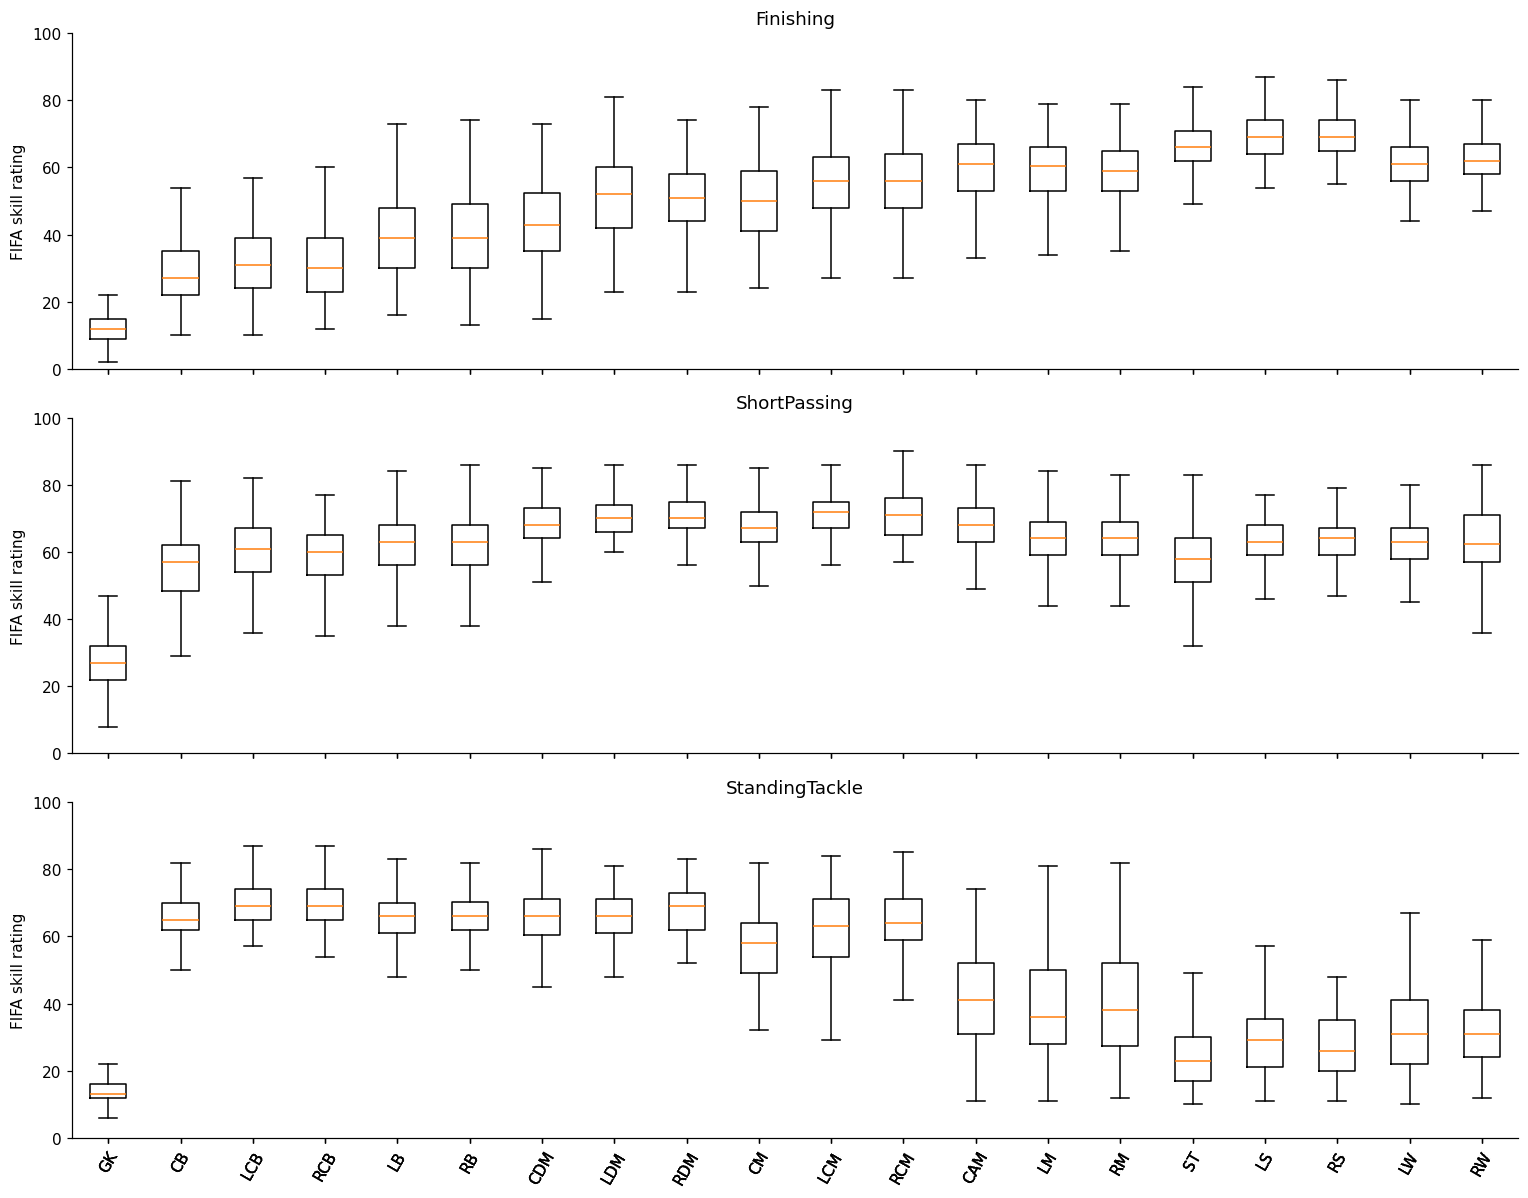

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for ax, feature in zip(axes, ['Finishing', 'ShortPassing', 'StandingTackle']):
    ax.boxplot([base_train.loc[base_train['label'].eq(position), feature] for position in CLASSES],
               tick_labels=CLASSES, showfliers=False)
    ax.set(title=feature, ylabel='FIFA skill rating', ylim=(0, 100))
plt.setp(axes[-1].get_xticklabels(), rotation=60)
plt.tight_layout()
plt.show()

## Fitting four different classifiers

| Predictor | Model | Why it is included |
|---|---|---|
| `logreg` | Standardized logistic regression | A transparent linear baseline in skill space |
| `forest` | Random forest, 250 trees, minimum leaf size 3 | Nonlinear combinations of skills |
| `boost` | Histogram gradient boosting, 200 iterations | A second nonlinear score construction |
| `svc` | Standardized RBF support-vector classifier | Smooth nonlinear boundaries with probability estimates |

These fixed settings are the same as in the four-role notebook and were not selected on the test players. The scaler in the logistic pipeline is learned from `base_train` only. Boosting's automatic early stopping is not triggered at this training size; all 200 iterations run, with one tree per position and iteration, so this is the slowest cell in the notebook. We use two threads to keep resource use predictable.

The SVC uses `CalibratedClassifierCV` with five-fold sigmoid probability calibration inside classifier-training data only. Each fold fits its own scaler; the final classifier is fitted on the full classifier-training partition. This probability calibration is separate from the library's conformal S2 calibration.

In [11]:
classifiers = {'logreg': make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=SEED)),
               'forest': RandomForestClassifier(n_estimators=250, min_samples_leaf=3, max_features='sqrt',
                                                n_jobs=1, random_state=SEED),
               'boost': HistGradientBoostingClassifier(max_iter=200, max_leaf_nodes=15, learning_rate=0.08,
                                                       l2_regularization=1.0, random_state=SEED),
               'svc': CalibratedClassifierCV(
                   make_pipeline(StandardScaler(), SVC(C=3.0, kernel='rbf', random_state=SEED)),
                   method='sigmoid', cv=5, ensemble=False),}
classifier_fit_seconds = {}
with threadpool_limits(limits=2):
    for name, classifier in classifiers.items():
        start = perf_counter()
        classifier.fit(base_train[FEATURES], base_train['label'])
        classifier_fit_seconds[name] = perf_counter() - start
        assert set(classifier.classes_) == set(CLASSES)
        print(f'{name}: fitted on {len(base_train):,} players in {classifier_fit_seconds[name]:.2f}s')

logreg: fitted on 7,133 players in 1.12s
forest: fitted on 7,133 players in 5.57s


c:\Users\PMLS\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\PMLS\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\PMLS\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\PMLS\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\PMLS\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

boost: fitted on 7,133 players in 9.60s
svc: fitted on 7,133 players in 6.80s


### Validation: is there useful class information?

Before envelope fitting, evaluate the fixed classifiers on validation players. Accuracy measures the best single-position prediction; macro recall is the average of each position's recall, so a large position cannot hide poor results on small ones; log loss assesses the full probability vector, with lower values better. None of these is conformal coverage.

Because positions on opposite sides are easy to confuse, we also report **role accuracy**: how often the predicted position belongs to the correct broad role (Goalkeeper, Defender, Midfielder, Attacker). It is the number most comparable with the four-role notebook.

In [12]:
validation_rows, validation_class_rows = [], []
true_roles = validation_players['label'].map(position_to_role).to_numpy()
with threadpool_limits(limits=2):
    for name, classifier in classifiers.items():
        probabilities = classifier.predict_proba(validation_players[FEATURES])
        chosen = classifier.classes_[probabilities.argmax(axis=1)]
        chosen_roles = pd.Series(chosen).map(position_to_role).to_numpy()
        validation_rows.append({'predictor': name,
            'accuracy': accuracy_score(validation_players['label'], chosen),
            'macro_recall': recall_score(validation_players['label'], chosen, labels=CLASSES,
                                         average='macro', zero_division=0),
            'role_accuracy': (chosen_roles == true_roles).mean(),
            'log_loss': log_loss(validation_players['label'], probabilities, labels=classifier.classes_)})
        for position in CLASSES:
            mask = validation_players['label'].eq(position).to_numpy()
            validation_class_rows.append({'predictor': name, 'position': position, 'n_validation': int(mask.sum()),
                                          'recall': (chosen[mask] == position).mean()})
validation_summary = pd.DataFrame(validation_rows).set_index('predictor')
display(validation_summary.round(4))

,accuracy,macro_recall,role_accuracy,log_loss
predictor,,,,
logreg,0.5301,0.3201,0.8893,1.2967
forest,0.5195,0.2988,0.8766,1.3995
boost,0.5189,0.3170,0.8842,1.5449
svc,0.5338,0.3107,0.8865,1.4445


In [13]:
validation_by_position = pd.DataFrame(validation_class_rows)
recall_table = validation_by_position.pivot(index='position', columns='predictor', values='recall').loc[CLASSES]
recall_table.insert(0, 'n_validation', validation_players['label'].value_counts().reindex(CLASSES).to_numpy())
display(recall_table.round(3))
validation_summary.to_csv(OUTPUT_DIR / 'validation_metrics.csv')
validation_by_position.to_csv(OUTPUT_DIR / 'validation_position_recall.csv', index=False)

predictor,n_validation,boost,forest,logreg,svc
position,,,,,
GK,405,1.000,1.000,1.000,1.000
CB,355,0.721,0.856,0.772,0.862
LCB,130,0.138,0.000,0.085,0.023
RCB,132,0.152,0.023,0.106,0.015
LB,264,0.508,0.500,0.530,0.489
RB,258,0.450,0.430,0.496,0.539
CDM,190,0.500,0.511,0.526,0.537
LDM,49,0.000,0.000,0.000,0.000
RDM,50,0.000,0.000,0.000,0.000


## Convert skills into the library's score-table format

Raw skill measurements do not go directly into the envelope library. The classifiers turn them into probabilities: **one per candidate position and predictor**, so four scores for every kept position. `ST_forest`, for example, is the forest's estimated probability of the candidate ST.

`label_to_columns` assigns exactly four scores to each candidate. On fitting ST's envelope, the library uses ST-labeled rows and ST's four columns. On prediction, every player's ST scores are tested against that region, and the same is done for every other kept position.

We read `classifier.classes_` when assigning columns; alphabetical probability-column order must not be confused with our display order. Test truth is kept separately and aligned by unique ID.

In [14]:
PREDICTORS = list(classifiers)
label_to_columns = {label: [f'{label}_{name}' for name in PREDICTORS] for label in CLASSES}
score_cols = [column for label in CLASSES for column in label_to_columns[label]]

def make_score_frame(frame):
    scores = pd.DataFrame({'ID': frame['ID'].to_numpy()})
    for name, classifier in classifiers.items():
        probabilities = classifier.predict_proba(frame[FEATURES])
        assert np.isfinite(probabilities).all()
        assert np.allclose(probabilities.sum(axis=1), 1)
        for j, label in enumerate(classifier.classes_):
            scores[f'{label}_{name}'] = probabilities[:, j]
    scores = scores[['ID', *score_cols]]
    assert scores['ID'].is_unique
    assert scores[score_cols].ge(0).all().all() and scores[score_cols].le(1).all().all()
    return scores

conformal_scores = make_score_frame(conformal_train)
conformal_scores['label'] = conformal_train['label'].to_numpy()
test_scores = make_score_frame(test_players)
test_truth = test_players.set_index('ID')['label']
assert 'label' not in test_scores.columns
assert conformal_scores[score_cols].notna().all().all()
assert test_scores[score_cols].notna().all().all()
display(pd.DataFrame(label_to_columns, index=[f'score {i + 1}' for i in range(len(PREDICTORS))]).T.rename_axis('candidate position'))

,score 1,score 2,score 3,score 4
candidate position,,,,
GK,GK_logreg,GK_forest,GK_boost,GK_svc
CB,CB_logreg,CB_forest,CB_boost,CB_svc
LCB,LCB_logreg,LCB_forest,LCB_boost,LCB_svc
RCB,RCB_logreg,RCB_forest,RCB_boost,RCB_svc
LB,LB_logreg,LB_forest,LB_boost,LB_svc
RB,RB_logreg,RB_forest,RB_boost,RB_svc
CDM,CDM_logreg,CDM_forest,CDM_boost,CDM_svc
LDM,LDM_logreg,LDM_forest,LDM_boost,LDM_svc
RDM,RDM_logreg,RDM_forest,RDM_boost,RDM_svc


In [15]:
display(conformal_scores[['ID', 'label', *score_cols[:6]]].head().round(4))
print(f'Conformal table: {conformal_scores.shape} | Test table: {test_scores.shape} | '
      f'{len(score_cols)} score columns = {len(CLASSES)} positions x {len(PREDICTORS)} predictors')

,ID,label,GK_logreg,GK_forest,GK_boost,GK_svc,CB_logreg,CB_forest
0,fifa19:236898,CM,0.0002,0.0,0.0,0.0002,0.0005,0.0042
1,fifa19:244892,CAM,0.0000,0.0,0.0,0.0002,0.0000,0.0000
2,fifa19:202977,CB,0.0000,0.0,0.0,0.0002,0.0022,0.0379
3,fifa19:166072,CB,0.0000,0.0,0.0,0.0001,0.7115,0.5063
4,fifa19:192991,ST,0.0000,0.0,0.0,0.0001,0.0000,0.0000


Conformal table: (5351, 82) | Test table: (1784, 81) | 80 score columns = 20 positions x 4 predictors


## Following one player from skills to scores

High probability supports a candidate. The library converts each coordinate $p$ to $1-p$, so low nonconformity supports the candidate.

These coordinates are not yet the method's combined calibration statistic. With many candidates we show the eight most probable positions (by mean probability across the four predictors) plus the true position.

In [16]:
example = conformal_scores.iloc[0]
player_info = conformal_train.set_index('ID').loc[example['ID']]
print(player_info['Name'], '| recorded position:', player_info['Position'], '| true broad role:', position_to_role[example['label']])
score_view = pd.DataFrame({name: [example[f'{position}_{name}'] for position in CLASSES] for name in PREDICTORS},
                          index=pd.Index(CLASSES, name='candidate position'))
shown = score_view.mean(axis=1).sort_values(ascending=False).index[:8].tolist()
if example['label'] not in shown:
    shown.append(example['label'])
print('Probabilities:')
display(score_view.loc[shown].round(4))

M. Aebischer | recorded position: CM | true broad role: Midfielder
Probabilities:


,logreg,forest,boost,svc
candidate position,,,,
CM,0.3780,0.4493,0.7212,0.4548
CAM,0.1449,0.0764,0.0173,0.1653
LCM,0.0803,0.0558,0.0450,0.1250
CDM,0.0367,0.0924,0.0224,0.1177
RCM,0.0643,0.0663,0.0888,0.0380
RM,0.1018,0.0596,0.0307,0.0406
LM,0.0667,0.0543,0.0448,0.0134
LDM,0.0526,0.0329,0.0170,0.0211


In [17]:
print('Coordinate-wise nonconformity:')
display((1 - score_view.loc[shown]).round(4))

Coordinate-wise nonconformity:


,logreg,forest,boost,svc
candidate position,,,,
CM,0.6220,0.5507,0.2788,0.5452
CAM,0.8551,0.9236,0.9827,0.8347
LCM,0.9197,0.9442,0.9550,0.8750
CDM,0.9633,0.9076,0.9776,0.8823
RCM,0.9357,0.9337,0.9112,0.9620
RM,0.8982,0.9404,0.9693,0.9594
LM,0.9333,0.9457,0.9552,0.9866
LDM,0.9474,0.9671,0.9830,0.9789


## Fitting the three conformal envelope methods

- **Collapsed:** averages the candidate's observed nonconformity coordinates.
- **Radial:** learns a direction-dependent boundary in score space.
- **Strip:** learns constraints involving pairs of score coordinates.

S1 learns the shape; S2 calibrates a threshold. The classwise finite-sample order is $k=\lceil(n_{S2}+1)(1-\alpha)\rceil$. Larger S2 gives finer rank resolution, not automatic predictive information. At `alpha=0.10`, the nominal target remains 90%.

Positions near the minimum size have small S2 sets, so their thresholds are coarse. With `n_S2 = 11` (reachable if you lower the minimum to 60), `k = 11`, so the threshold is the **largest** calibration score. The guarantee still holds, but those positions tend to get wide regions and larger sets.

**Updated radial rule:** radial fitting takes the coordinatewise downward closure of sampled S1 boundary points, then recalibrates this monotone score on S2. Improving any observed coordinate (with the missingness pattern unchanged) preserves acceptance. The finite boundary sampling can produce small steps in plots. Refit older saved models to use this rule.

In [18]:
models, fit_times = {}, {}
for method, params in METHOD_PARAMS.items():
    model = ConformalSetModel(method=method, alpha=ALPHA, random_state=SEED,
                              score_direction='higher_is_better', shape_fraction=SHAPE_FRACTION,
                              force_nonempty=False, **params)
    start = perf_counter()
    model.fit(conformal_scores, id_col='ID', label_col='label', score_cols=score_cols,
              label_to_columns=label_to_columns)
    fit_times[method] = perf_counter() - start
    models[method] = model
    print(f'{method}: fitted in {fit_times[method]:.2f}s')

collapsed: fitted in 0.07s
radial: fitted in 0.24s
strip: fitted in 0.28s


### Verifying the actual calibration counts

`t_hat` is a geometric scaling threshold, not coverage or a probability. Its numerical scale differs across methods. Every position must have a finite `t_hat`; an infinite one would mean the position accepts every player. The S1/S2 sizes must also agree with the arithmetic we checked before fitting.

In [19]:
envelope_rows = []
for method, model in models.items():
    for label, info in model.get_envelopes().items():
        n_cal = info['calibration_size']
        rank = int(np.ceil((n_cal + 1) * (1 - ALPHA)))
        envelope_rows.append({'method': method, 'class': label, 'shape_n': info['shape_size'],
            'calibration_n': n_cal, 'rank_step': 1 / (n_cal + 1),
            'quantile_rank': rank, 'too_few_for_finite_rank': rank > n_cal,
            'infinite_threshold': not np.isfinite(info['envelope']['t_hat']),
            't_hat': info['envelope']['t_hat']})
envelope_summary = pd.DataFrame(envelope_rows)
assert set(envelope_summary['class']) == set(CLASSES)
assert not envelope_summary['too_few_for_finite_rank'].any(), 'Raise MIN_PLAYERS_PER_POSITION.'
assert np.isfinite(envelope_summary['t_hat']).all(), 'Investigate an infinite threshold.'
expected_s2 = envelope_summary['class'].map(feasibility['S2_n'])
assert (envelope_summary['calibration_n'] == expected_s2).all(), 'Library S2 sizes differ from the pre-fit check.'
print(f'Smallest S2 set: {envelope_summary["calibration_n"].min()} rows | '
      f'largest rank step: {envelope_summary["rank_step"].max():.4f}')
display(envelope_summary[envelope_summary['method'].eq('collapsed')].sort_values('calibration_n').head(8).round(5))
envelope_summary.to_csv(OUTPUT_DIR / 'envelope_summary.csv', index=False)

Smallest S2 set: 31 rows | largest rank step: 0.0312


,method,class,shape_n,calibration_n,rank_step,quantile_rank,too_few_for_finite_rank,infinite_threshold,t_hat
17,collapsed,RS,30,31,0.03125,29,False,False,1.00092
10,collapsed,LS,31,31,0.03125,29,False,False,0.99803
15,collapsed,RDM,37,37,0.02632,35,False,False,1.01074
8,collapsed,LDM,36,37,0.02632,35,False,False,1.01084
18,collapsed,RW,55,56,0.01754,52,False,False,1.00639
11,collapsed,LW,57,57,0.01724,53,False,False,1.00353
14,collapsed,RCM,58,59,0.01667,54,False,False,1.02432
7,collapsed,LCM,59,59,0.01667,54,False,False,1.00329


## Predicting sets

Each player receives the positions whose envelopes accept that player's score vector. A singleton is one accepted position, a larger set expresses ambiguity, a full set accepts every kept position, and an empty set accepts none. **Smaller is useful only if coverage remains adequate.** We evaluate every retained test player, including ambiguous cases. Averages are reported against the number of candidate positions, because a set of size 5 is very different out of 4 labels than out of 23.

In [20]:
predictions, predict_times = {}, {}
for method, model in models.items():
    start = perf_counter()
    result = model.predict(test_scores)
    predict_times[method] = perf_counter() - start
    assert result['ID'].is_unique and set(result['ID']) == set(test_scores['ID'])
    assert (result['set_size'] == result['prediction_set'].map(len)).all()
    assert result['prediction_set'].map(lambda s: set(s).issubset(CLASSES)).all()
    assert not result['forced'].any()
    predictions[method] = result
SELECTED_METHOD = 'strip'  # For inspection only; not chosen by test performance.
display(predictions[SELECTED_METHOD][['ID', 'prediction_set', 'set_size']].head(12))

,ID,prediction_set,set_size
0,fifa19:236345,"[CAM, LCM, LDM, LM, LS, LW, RCM, RM, RS, RW]",10
1,fifa19:214254,"[CB, LCB, RCB]",3
2,fifa19:221376,"[CB, LCB, RCB]",3
3,fifa19:193195,"[CAM, LCM, LM, LS, LW, RM, RS, RW, ST]",9
4,fifa19:213151,"[CB, LB, LDM, RB]",4
5,fifa19:239126,"[LB, RB]",2
6,fifa19:206145,[GK],1
7,fifa19:212000,"[LM, LS, LW, RM, RS, RW]",6
8,fifa19:200233,"[CAM, LCM, LM, LS, LW, RM, RW]",7
9,fifa19:193348,"[CAM, LCM, LDM, LM, LW, RCM, RM, RW]",8


### Independent check of the collapsed acceptance rule

To check score ordering and threshold application, we reconstruct the collapsed decision using only that model's stored S2 indices. For each position, take the finite-sample quantile of the mean `1 - probability` on its true-position S2 rows, then compare every test player's corresponding score with that threshold.

This is a diagnostic, not another method used to generate our results. It should exactly match the library's decisions on this dataset. It does not independently validate the radial or strip geometry.

In [21]:
manual_checks = []
for position, info in models['collapsed'].get_envelopes().items():
    columns = label_to_columns[position]
    true_position_scores = conformal_scores.loc[conformal_scores['label'].eq(position), columns].to_numpy()
    s2_means = (1 - true_position_scores[info['idx_s2']]).mean(axis=1)
    rank = int(np.ceil((len(s2_means) + 1) * (1 - ALPHA)))
    threshold = np.sort(s2_means)[rank - 1] if rank <= len(s2_means) else np.inf
    manual_membership = (1 - test_scores[columns].to_numpy()).mean(axis=1) <= threshold
    library_membership = predictions['collapsed']['prediction_set'].map(lambda labels: position in labels).to_numpy()
    assert np.array_equal(manual_membership, library_membership), f'Membership mismatch for {position}'
    manual_checks.append({'position': position, 'S2_n': len(s2_means), 'rank': rank,
                          'threshold_in_mean_nonconformity': threshold,
                          'matching_decisions': len(manual_membership)})
manual_table = pd.DataFrame(manual_checks)
print(f'Collapsed rule reproduced exactly for all {len(manual_table)} positions.')
display(manual_table.head(8))

Collapsed rule reproduced exactly for all 20 positions.


,position,S2_n,rank,threshold_in_mean_nonconformity,matching_decisions
0,CAM,144,131,0.954902,1784
1,CB,267,242,0.852629,1784
2,CDM,142,129,0.934036,1784
3,CM,210,190,0.839998,1784
4,GK,304,275,0.070480,1784
5,LB,199,180,0.837828,1784
6,LCB,97,89,0.939123,1784
7,LCM,59,54,0.986009,1784


## Evaluating coverage and efficiency together

| Metric | Meaning |
|---|---|
| Coverage | Fraction of players whose set includes their recorded position |
| Macro coverage | Mean of the per-position coverages, so large positions do not dominate |
| Average set size | Mean accepted positions, out of the kept candidates |
| Fraction of label space | Average set size divided by the number of kept positions |
| Singleton rate | Fraction receiving exactly one position |
| Singleton accuracy | Accuracy among singleton sets; undefined if there are none |
| Empty rate | Fraction receiving no position; these are all uncovered |

With this many neighbouring positions, singletons will be rare. A useful result here is a set that stays small relative to the label space while holding coverage near 90%.

In [22]:
summary_rows, class_rows = [], []
for method, result in predictions.items():
    truth = test_truth.loc[result['ID']].to_numpy()
    covered = np.array([y in labels for y, labels in zip(truth, result['prediction_set'])])
    metrics = evaluate_prediction_sets(result['prediction_set'], truth.tolist())
    assert np.isclose(metrics['coverage'], covered.mean())
    per_class = {label: covered[truth == label].mean() for label in CLASSES if (truth == label).any()}
    summary_rows.append({'method': method, **{k: v for k, v in metrics.items() if k != 'per_class_coverage'},
                         'macro_coverage': float(np.mean(list(per_class.values()))),
                         'fraction_of_label_space': metrics['average_set_size'] / len(CLASSES),
                         'n_test': len(result), 'n_covered': int(covered.sum()),
                         'fit_seconds': fit_times[method], 'predict_seconds': predict_times[method]})
    for label in CLASSES:
        mask = truth == label
        class_rows.append({'method': method, 'class': label, 'broad_role': position_to_role[label],
                           'n_test': int(mask.sum()), 'n_covered': int(covered[mask].sum()),
                           'coverage': covered[mask].mean() if mask.any() else np.nan,
                           'average_set_size': result.loc[mask, 'set_size'].mean() if mask.any() else np.nan})
summary = pd.DataFrame(summary_rows).set_index('method')
class_summary = pd.DataFrame(class_rows)
display(summary.round(4))

,coverage,average_set_size,singleton_rate,singleton_accuracy,empty_rate,macro_coverage,fraction_of_label_space,n_test,n_covered,fit_seconds,predict_seconds
method,,,,,,,,,,,
collapsed,0.9249,4.7511,0.1076,0.9896,0.0095,0.9281,0.2376,1784,1650,0.0728,0.2182
radial,0.9002,4.5757,0.0987,1.0000,0.0168,0.9019,0.2288,1784,1606,0.2417,0.5605
strip,0.9288,4.9058,0.1205,0.9674,0.0078,0.9337,0.2453,1784,1657,0.2766,0.1431


In [23]:
by_position = class_summary.pivot(index='class', columns='method', values='coverage').loc[CLASSES]
size_by_position = class_summary.pivot(index='class', columns='method', values='average_set_size').loc[CLASSES]
by_position.insert(0, 'n_test', class_summary.loc[class_summary['method'].eq('collapsed')].set_index('class')['n_test'].loc[CLASSES])
print('Coverage by position (single test draw; small n_test makes these noisy):')
display(by_position.round(3))
print('Average set size by position:')
display(size_by_position.round(2))
summary.to_csv(OUTPUT_DIR / 'metrics.csv')
class_summary.to_csv(OUTPUT_DIR / 'class_metrics.csv', index=False)

Coverage by position (single test draw; small n_test makes these noisy):


method,n_test,collapsed,radial,strip
class,,,,
GK,203,0.916,0.852,0.931
CB,178,0.938,0.921,0.938
LCB,65,0.908,0.862,0.923
RCB,66,0.924,0.909,0.879
LB,132,0.856,0.856,0.864
RB,129,0.868,0.907,0.899
CDM,95,0.926,0.916,0.958
LDM,24,0.958,0.917,1.000
RDM,25,0.920,0.840,0.920


Average set size by position:


method,collapsed,radial,strip
class,,,
GK,0.92,0.85,0.93
CB,4.07,3.28,3.73
LCB,4.88,3.51,4.45
RCB,4.92,3.64,4.56
LB,4.20,3.45,4.63
RB,4.24,3.64,4.76
CDM,5.89,5.48,6.11
LDM,6.29,6.25,6.38
RDM,6.48,6.52,6.48


## Repeating the conformal and test draw

The table above comes from a single random draw of the conformal and test players, so its coverage is only one sample, and the per-position rows rest on very few test players (the rarest kept positions have single-digit test counts). To measure the guarantee itself, the cell below pools the conformal and test players and re-splits them at random 100 times, with the same sizes, stratified by position, and refits all three methods each time. Only this draw changes; the four trained classifiers stay fixed. Empty sets count as errors.

Pooling over 100 repetitions gives every position hundreds of evaluated players, so the per-position averages below are far more reliable than the single-draw table. This cell is the slowest evaluation step (the radial method must evaluate every position for every test player).

In [24]:
# Repeating the conformal fit and the test draw many times with the SAME trained predictors.
# The conformal and test players are pooled and re-split at random, with the same sizes and stratified by position.
N_REPEATS = 100

pool = pd.concat([conformal_scores,
                  test_scores.assign(label=test_truth.reindex(test_scores['ID']).to_numpy())], ignore_index=True)
repeat_rows = []
for rep in range(N_REPEATS):
    rep_cal, rep_test = train_test_split(pool, test_size=len(test_scores), stratify=pool['label'],
                                         random_state=1000 + rep)
    for method, params in METHOD_PARAMS.items():
        rep_model = ConformalSetModel(method=method, alpha=ALPHA, random_state=rep,
                                      score_direction='higher_is_better', shape_fraction=SHAPE_FRACTION,
                                      force_nonempty=False, **params)
        rep_model.fit(rep_cal, id_col='ID', label_col='label', score_cols=score_cols,
                      label_to_columns=label_to_columns)
        result = rep_model.predict(rep_test[['ID', *score_cols]])
        truth = rep_test.set_index('ID').loc[result['ID'], 'label'].to_numpy()
        covered = np.array([y in labels for y, labels in zip(truth, result['prediction_set'])])
        sizes = result['set_size'].to_numpy()
        row = {'rep': rep, 'method': method, 'coverage': covered.mean(), 'average_set_size': sizes.mean(),
               'singleton_rate': (sizes == 1).mean(), 'empty_rate': (sizes == 0).mean()}
        for label in CLASSES:
            row[f'coverage_{label}'] = covered[truth == label].mean() if (truth == label).any() else np.nan
        row['macro_coverage'] = np.nanmean([row[f'coverage_{label}'] for label in CLASSES])
        truth_roles = pd.Series(truth).map(position_to_role).to_numpy()
        for role in ROLES:
            in_role = truth_roles == role
            row[f'coverage_role_{role}'] = covered[in_role].mean() if in_role.any() else np.nan
            row[f'size_role_{role}'] = sizes[in_role].mean() if in_role.any() else np.nan
        repeat_rows.append(row)

repeat_results = pd.DataFrame(repeat_rows)
repeat_columns = ['coverage', 'macro_coverage', 'average_set_size', 'singleton_rate', 'empty_rate']
repeat_summary = repeat_results.groupby('method', sort=False)[repeat_columns].agg(['mean', 'std'])
print('Mean and standard deviation across repetitions:')
display(repeat_summary.round(4))
print('Standard error of the mean:')
display((repeat_summary.xs('std', axis=1, level=1) / np.sqrt(N_REPEATS)).round(4))
print(f'Nominal coverage target: {1 - ALPHA:.0%}')
repeat_results.to_csv(OUTPUT_DIR / 'repeated_runs.csv', index=False)

Mean and standard deviation across repetitions:


coverage         macro_coverage         average_set_size          \
              mean     std           mean     std             mean     std   
method                                                                       
collapsed   0.9032  0.0091         0.9052  0.0110           4.3645  0.1665   
radial      0.9016  0.0087         0.9037  0.0107           4.7380  0.2226   
strip       0.9016  0.0092         0.9040  0.0118           4.5750  0.1483   

          singleton_rate         empty_rate          
                    mean     std       mean     std  
method                                               
collapsed         0.1084  0.0046     0.0104  0.0035  
radial            0.1013  0.0188     0.0103  0.0044  
strip             0.1179  0.0060     0.0108  0.0032

Standard error of the mean:


,coverage,macro_coverage,average_set_size,singleton_rate,empty_rate
method,,,,,
collapsed,0.0009,0.0011,0.0167,0.0005,0.0004
radial,0.0009,0.0011,0.0223,0.0019,0.0004
strip,0.0009,0.0012,0.0148,0.0006,0.0003


Nominal coverage target: 90%


In [25]:
class_cols = [f'coverage_{label}' for label in CLASSES]
repeat_by_position = repeat_results.groupby('method', sort=False)[class_cols].mean().T
repeat_by_position.index = CLASSES
repeat_by_position.insert(0, 'broad_role', [position_to_role[p] for p in CLASSES])
print('Mean coverage by position across repetitions:')
display(repeat_by_position.round(3))
numeric_methods = [m for m in METHOD_PARAMS]
worst = repeat_by_position[numeric_methods].min()
print('Lowest per-position mean coverage:', worst.round(3).to_dict())
repeat_by_position.rename_axis('position').to_csv(OUTPUT_DIR / 'repeated_position_coverage.csv')

role_repeat_rows = []
for method, group in repeat_results.groupby('method', sort=False):
    for role in ROLES:
        role_repeat_rows.append({'method': method, 'true_role': role,
                                 'positions_in_role': sum(position_to_role[p] == role for p in CLASSES),
                                 'coverage': group[f'coverage_role_{role}'].mean(),
                                 'average_set_size': group[f'size_role_{role}'].mean()})
repeat_by_role = pd.DataFrame(role_repeat_rows)
print('Coverage and set size by true broad role, averaged over repetitions:')
display(repeat_by_role.round(3))
repeat_by_role.to_csv(OUTPUT_DIR / 'repeated_role_metrics.csv', index=False)

Mean coverage by position across repetitions:


method,broad_role,collapsed,radial,strip
GK,Goalkeeper,0.907,0.898,0.905
CB,Defender,0.903,0.903,0.903
LCB,Defender,0.910,0.906,0.907
RCB,Defender,0.900,0.897,0.895
LB,Defender,0.897,0.895,0.896
RB,Defender,0.899,0.903,0.896
CDM,Midfielder,0.900,0.900,0.901
LDM,Midfielder,0.916,0.926,0.926
RDM,Midfielder,0.923,0.916,0.926
CM,Midfielder,0.898,0.897,0.899


Lowest per-position mean coverage: {'collapsed': 0.888, 'radial': 0.895, 'strip': 0.895}
Coverage and set size by true broad role, averaged over repetitions:


,method,true_role,positions_in_role,coverage,average_set_size
0,collapsed,Goalkeeper,1,0.907,0.909
1,collapsed,Defender,5,0.901,3.786
2,collapsed,Midfielder,9,0.902,5.812
3,collapsed,Attacker,5,0.907,4.505
4,radial,Goalkeeper,1,0.898,0.970
5,radial,Defender,5,0.901,4.133
6,radial,Midfielder,9,0.902,6.254
7,radial,Attacker,5,0.904,4.978
8,strip,Goalkeeper,1,0.905,0.905
9,strip,Defender,5,0.899,3.887


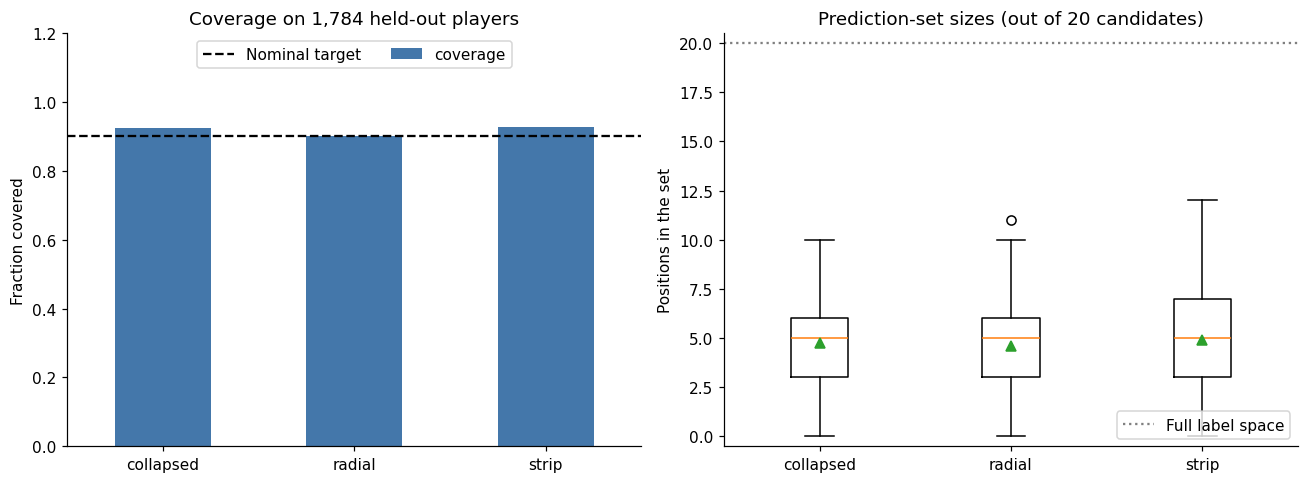

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
summary['coverage'].plot.bar(ax=axes[0], rot=0, color='#4477aa')
axes[0].axhline(1 - ALPHA, color='black', linestyle='--', label='Nominal target')
axes[0].set(ylim=(0, 1.2), xlabel='', ylabel='Fraction covered', title=f'Coverage on {len(test_scores):,} held-out players')
axes[0].legend(loc='upper center', ncol=2)
size_data = [predictions[m]['set_size'].to_numpy() for m in predictions]
axes[1].boxplot(size_data, tick_labels=list(predictions), showmeans=True)
axes[1].set(ylim=(-0.5, len(CLASSES) + 0.5), xlabel='', ylabel='Positions in the set',
            title=f'Prediction-set sizes (out of {len(CLASSES)} candidates)')
axes[1].axhline(len(CLASSES), color='grey', linestyle=':', label='Full label space')
axes[1].legend(loc='lower right')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'coverage_and_set_sizes.png', bbox_inches='tight')
plt.show()

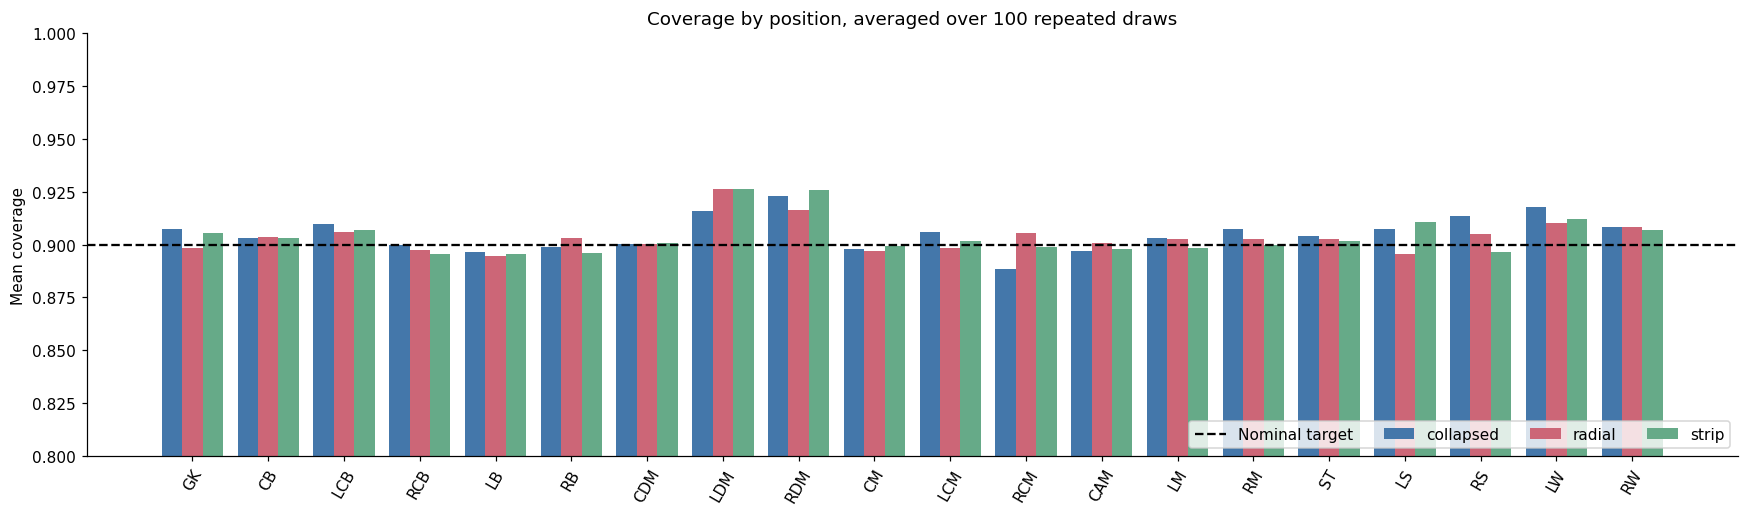

In [27]:
fig, ax = plt.subplots(figsize=(16, 4.8))
width = 0.27
positions_x = np.arange(len(CLASSES))
for i, (method, color) in enumerate(zip(METHOD_PARAMS, ['#4477aa', '#cc6677', '#66aa88'])):
    ax.bar(positions_x + (i - 1) * width, repeat_by_position[method].to_numpy(), width, label=method, color=color)
ax.axhline(1 - ALPHA, color='black', linestyle='--', label='Nominal target')
ax.set_xticks(positions_x, CLASSES, rotation=60)
ax.set(ylim=(0.8, 1.0), ylabel='Mean coverage', title=f'Coverage by position, averaged over {N_REPEATS} repeated draws')
ax.legend(ncol=4, loc='lower right')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'coverage_by_position.png', bbox_inches='tight')
plt.show()

## Inspecting ambiguity without hiding difficult players

We retain names for interpreting results, but names were not predictors. A set such as LCB/CB/RCB is expected for a central defender, because those positions differ by side rather than by skills. Measured coverage uses the declared single recorded position; plausible alternatives do not turn an uncovered prediction into a covered one.

The second table intentionally selects non-singleton or uncovered cases for discussion. It is not a representative performance sample.

In [28]:
metadata = test_players.set_index('ID')[['Name']]
evaluated = {}
for method, result in predictions.items():
    table = result.set_index('ID').join(metadata, validate='one_to_one')
    table['truth'] = test_truth.reindex(table.index)
    table['truth_role'] = table['truth'].map(position_to_role)
    table['covered'] = [position in labels for position, labels in zip(table['truth'], table['prediction_set'])]
    table['n_roles_in_set'] = [len({position_to_role[p] for p in labels}) for labels in table['prediction_set']]
    evaluated[method] = table
inspection = evaluated[SELECTED_METHOD][['Name', 'truth', 'prediction_set', 'set_size', 'covered']]
display(inspection.head(10))
display(inspection.loc[inspection['set_size'].ne(1) | ~inspection['covered']].head(15))

,Name,truth,prediction_set,set_size,covered
ID,,,,,
fifa19:236345,A. Totovytskyi,CAM,"[CAM, LCM, LDM, LM, LS, LW, RCM, RM, RS, RW]",10,True
fifa19:214254,B. San Juan,CB,"[CB, LCB, RCB]",3,True
fifa19:221376,A. Puljić,CB,"[CB, LCB, RCB]",3,True
fifa19:193195,N. Ben Khalifa,LW,"[CAM, LCM, LM, LS, LW, RM, RS, RW, ST]",9,True
fifa19:213151,C. Norman,RB,"[CB, LB, LDM, RB]",4,True
fifa19:239126,M. Al Baqawi,RB,"[LB, RB]",2,True
fifa19:206145,B. Uphoff,GK,[GK],1,True
fifa19:212000,E. Berko,RM,"[LM, LS, LW, RM, RS, RW]",6,True
fifa19:200233,A. Messaoud,CAM,"[CAM, LCM, LM, LS, LW, RM, RW]",7,True


,Name,truth,prediction_set,set_size,covered
ID,,,,,
fifa19:236345,A. Totovytskyi,CAM,"[CAM, LCM, LDM, LM, LS, LW, RCM, RM, RS, RW]",10,True
fifa19:214254,B. San Juan,CB,"[CB, LCB, RCB]",3,True
fifa19:221376,A. Puljić,CB,"[CB, LCB, RCB]",3,True
fifa19:193195,N. Ben Khalifa,LW,"[CAM, LCM, LM, LS, LW, RM, RS, RW, ST]",9,True
fifa19:213151,C. Norman,RB,"[CB, LB, LDM, RB]",4,True
fifa19:239126,M. Al Baqawi,RB,"[LB, RB]",2,True
fifa19:212000,E. Berko,RM,"[LM, LS, LW, RM, RS, RW]",6,True
fifa19:200233,A. Messaoud,CAM,"[CAM, LCM, LM, LS, LW, RM, RW]",7,True
fifa19:193348,X. Shaqiri,CAM,"[CAM, LCM, LDM, LM, LW, RCM, RM, RW]",8,True


### Do the sets stay within the right broad role?

Because left, right, and centre variants are hard to separate, a large set is not necessarily a confused one. The table groups the **single-draw** test players by their true broad role and reports, per method, the coverage, the average set size, and the share of non-empty sets whose members all belong to a **single** broad role. A high share means the ambiguity is mostly between neighbouring positions of the same role; a low share means sets also reach into other roles. Coverage in this table comes from one test draw and moves by several points from draw to draw for a role with few players; the repeated-draw role table above is the reliable one.

In [29]:
role_rows = []
for method, table in evaluated.items():
    for role in ROLES:
        part = table[table['truth_role'].eq(role)]
        if part.empty:
            continue
        nonempty = part[part['set_size'] > 0]
        role_rows.append({'method': method, 'true_role': role, 'n_test': len(part),
                          'coverage': part['covered'].mean(), 'average_set_size': part['set_size'].mean(),
                          'positions_in_role': len([p for p in CLASSES if position_to_role[p] == role]),
                          'single_role_sets': (nonempty['n_roles_in_set'] == 1).mean() if len(nonempty) else np.nan})
role_summary = pd.DataFrame(role_rows)
display(role_summary.round(3))
role_summary.to_csv(OUTPUT_DIR / 'role_metrics.csv', index=False)

,method,true_role,n_test,coverage,average_set_size,positions_in_role,single_role_sets
0,collapsed,Goalkeeper,203,0.916,0.916,1,1.000
1,collapsed,Defender,570,0.898,4.330,5,0.328
2,collapsed,Midfielder,680,0.944,6.240,9,0.449
3,collapsed,Attacker,331,0.937,4.770,5,0.366
4,radial,Goalkeeper,203,0.852,0.852,1,1.000
5,radial,Defender,570,0.895,3.467,5,0.691
6,radial,Midfielder,680,0.904,6.249,9,0.271
7,radial,Attacker,331,0.931,5.332,5,0.429
8,strip,Goalkeeper,203,0.931,0.931,1,1.000
9,strip,Defender,570,0.904,4.349,5,0.472


## Plotting acceptance regions in classifier-score space

The selected candidate and predictor axes below can be changed freely. `hidden_value = 0.5` is a valid fixed **nonconformity** coordinate for the hidden logistic predictor, not a calibration threshold. It affects only the displayed cross-section, not the fitted model or its predictions.

`plot_slice` displays the existing four-score envelope; test-point categories use each player's actual full score vector. `plot` fits a separate two-score diagnostic envelope. Its categories refer to that separate fit. The evaluation above always uses all four scores and all test players.

Two predictors are hidden in the slice. Logistic nonconformity retains your chosen 0.5 value; SVC nonconformity is fixed at its median among true-position conformal-fitting players. Both fixed values are shown on the plot.

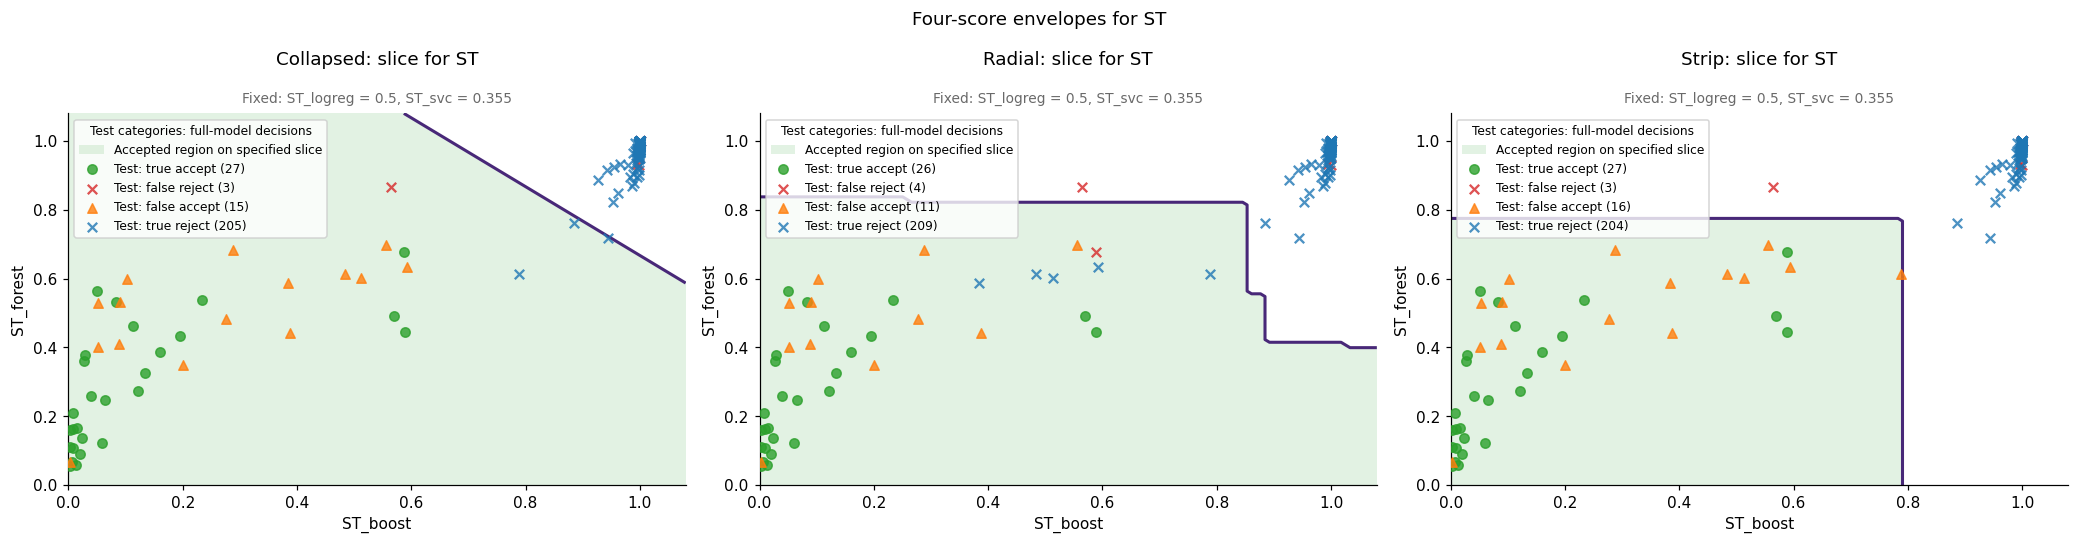

In [30]:
PLOT_LABEL = 'ST'   # any kept position, e.g. 'GK', 'CB', 'CM', 'LW'
assert PLOT_LABEL in CLASSES, f'{PLOT_LABEL} is not a kept position: {CLASSES}'
x, y = f'{PLOT_LABEL}_boost', f'{PLOT_LABEL}_forest'
hidden = f'{PLOT_LABEL}_logreg'
# hidden_value = float((1 - conformal_scores.loc[conformal_scores['label'].eq(PLOT_LABEL), hidden]).median())
hidden_value = 0.5
svc_hidden = f'{PLOT_LABEL}_svc'
svc_hidden_value = float((1 - conformal_scores.loc[conformal_scores['label'].eq(PLOT_LABEL), svc_hidden]).median())
plot_test = test_scores.sample(n=min(250, len(test_scores)), random_state=SEED).copy()
plot_test['label'] = test_truth.loc[plot_test['ID']].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (method, model) in zip(axes, models.items()):
    model.plot_slice(x=x, y=y, label=PLOT_LABEL, test_data=plot_test,
                     slice_values={hidden: hidden_value, svc_hidden: svc_hidden_value}, grid_size=70, show_training=False,
                     ax=ax, )
    fig.suptitle(f'Four-score envelopes for {PLOT_LABEL}')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'envelope_slices.png', bbox_inches='tight')
plt.show()

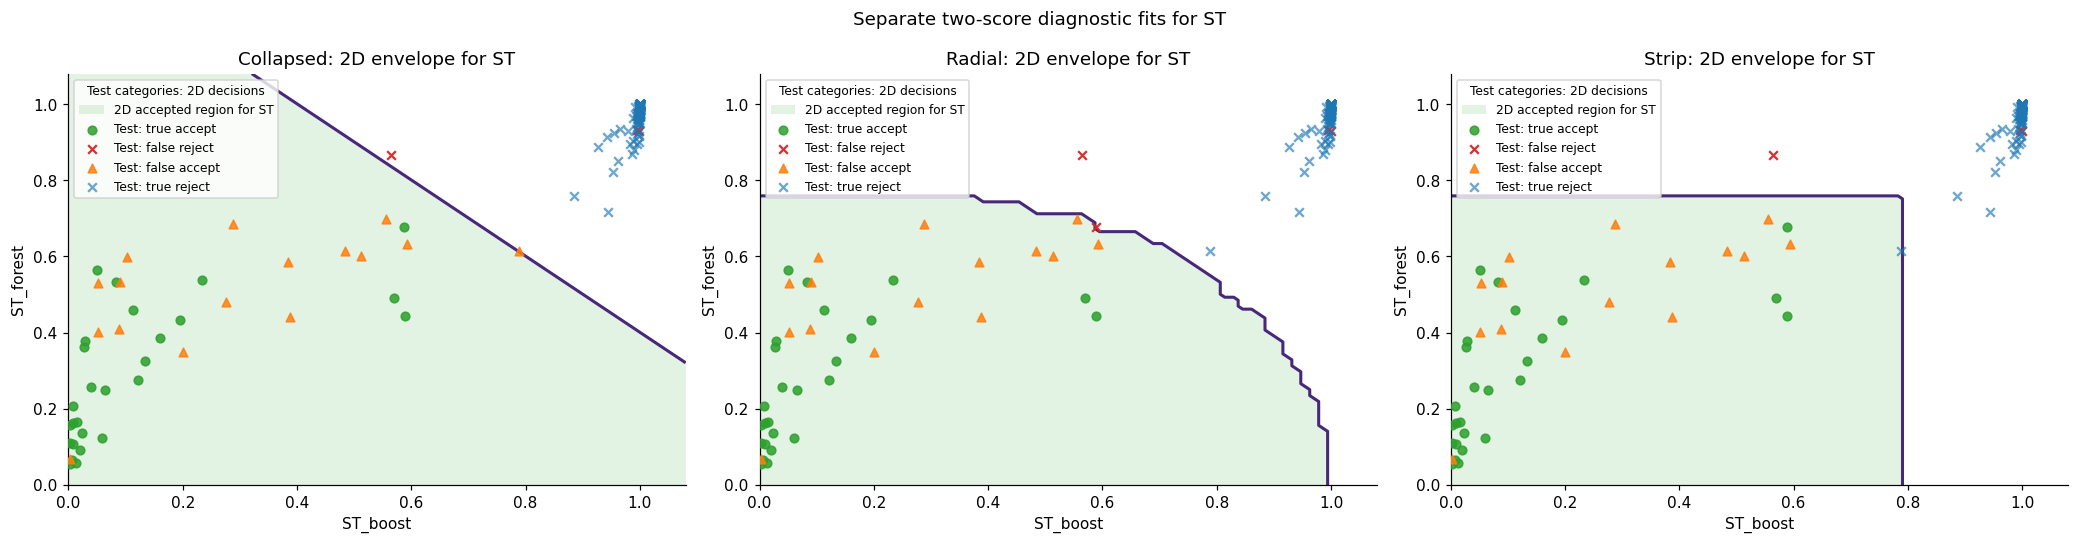

Plotting left all main-model predictions unchanged.


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (method, model) in zip(axes, models.items()):
    model.plot(x=x, y=y, label=PLOT_LABEL, test_data=plot_test,
               grid_size=70, show_training=False, show_other_classes=False, ax=ax)
fig.suptitle(f'Separate two-score diagnostic fits for {PLOT_LABEL}')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'two_dimensional_diagnostics.png', bbox_inches='tight')
plt.show()
for method, model in models.items():
    pd.testing.assert_frame_equal(model.predict(test_scores), predictions[method])
print('Plotting left all main-model predictions unchanged.')

### Class-inclusion heatmaps

Rows are true positions; columns are candidate positions, both ordered by broad role (goalkeeper, defenders, midfielders, attackers). The diagonal is per-position coverage. Off-diagonal entries show how often an alternative position is included, so bright blocks along the diagonal show ambiguity *within* a role, such as left/right/centre variants. Rows need not sum to one, because sets may accept more than one position. These are not ordinary confusion matrices.

With this many labels each method gets its own figure so the tick labels stay readable. Cell annotations are switched off; set `ANNOTATE_HEATMAPS = True` to print the rates.

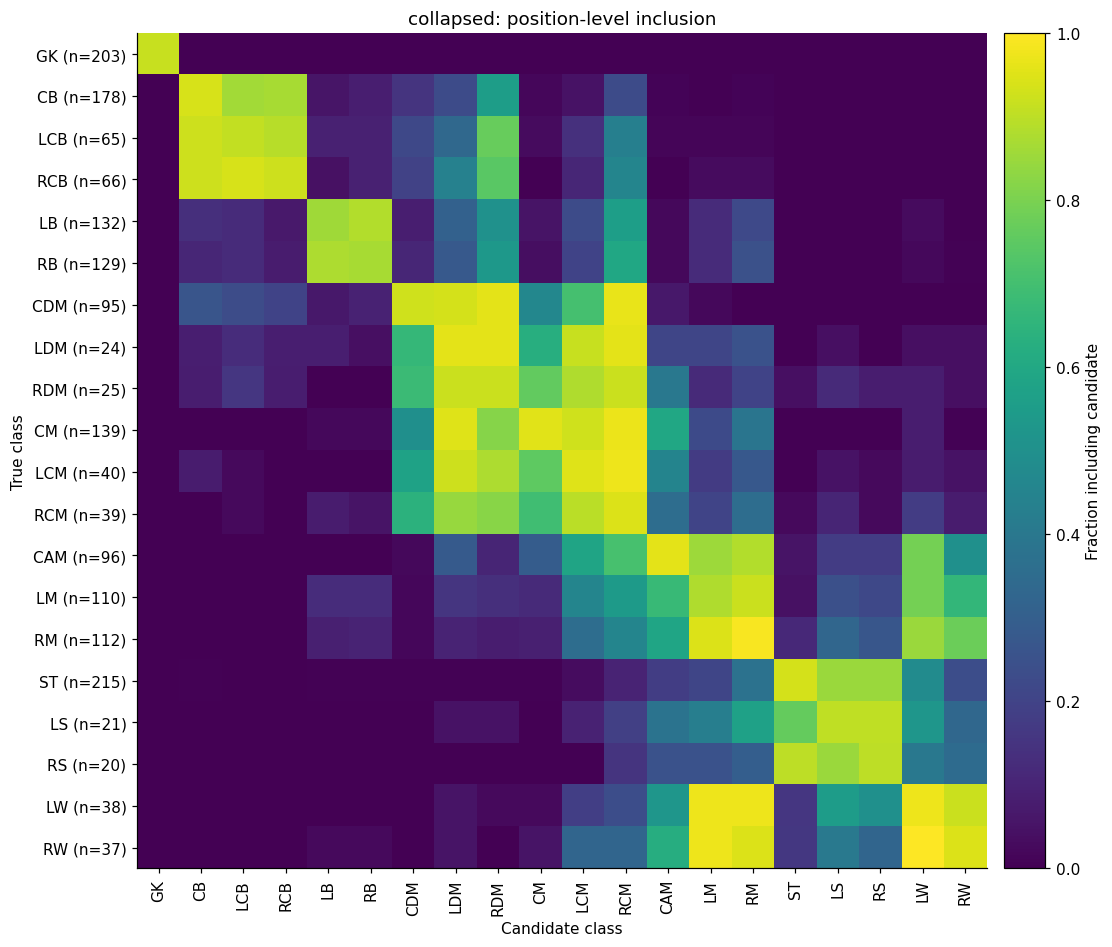

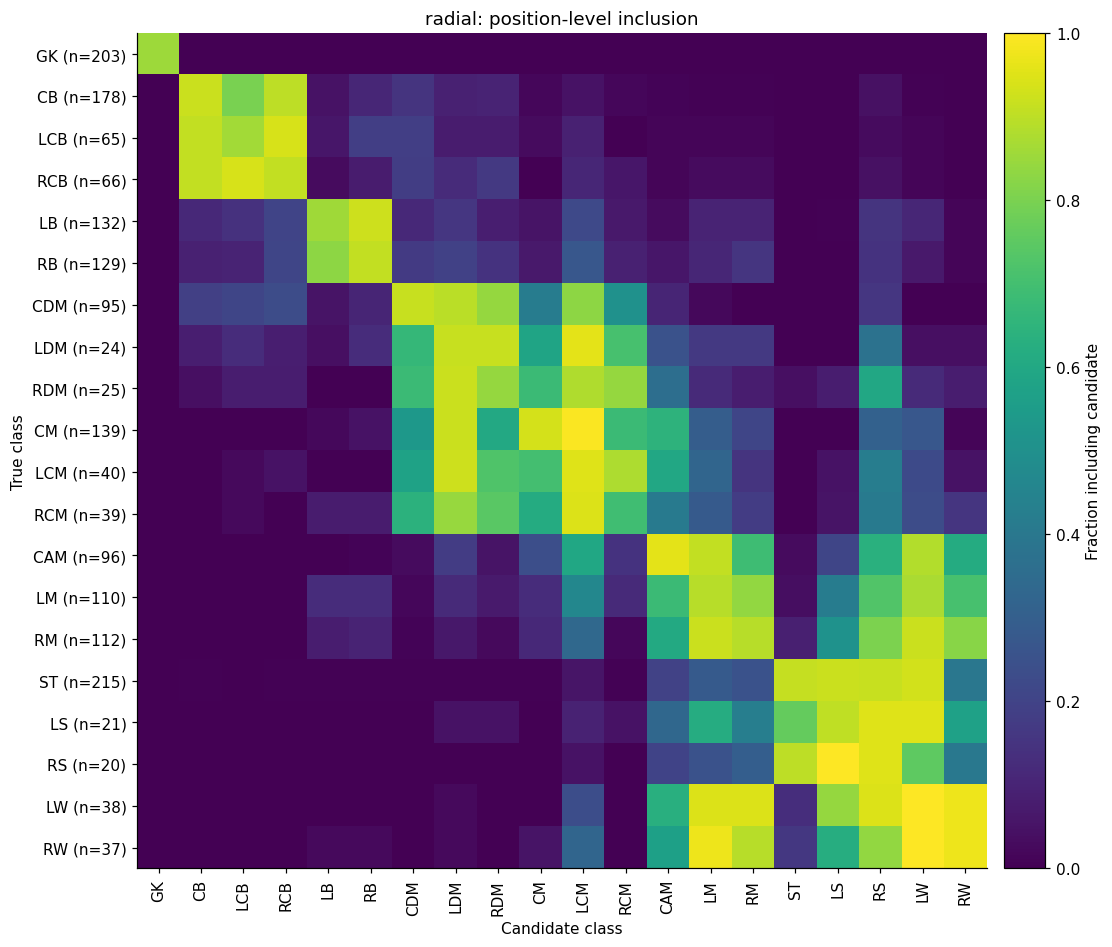

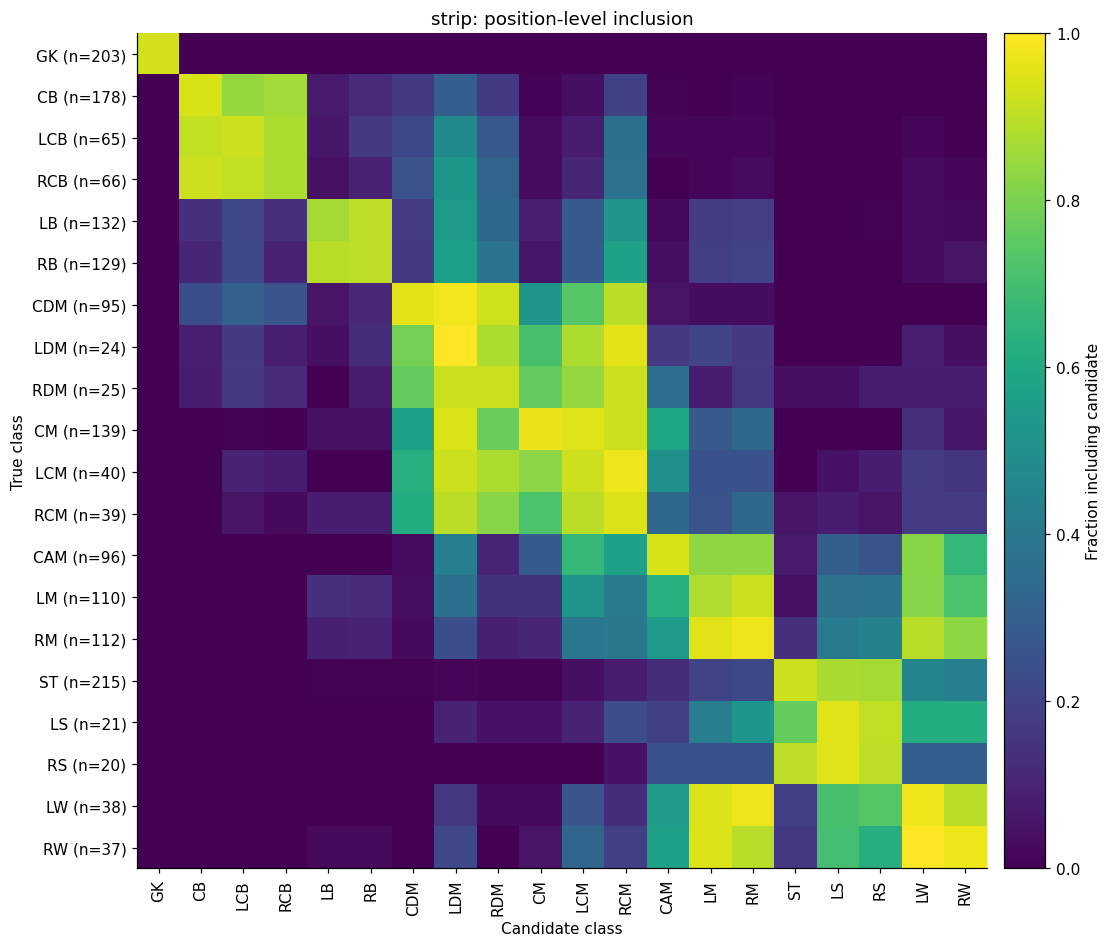

In [32]:
ANNOTATE_HEATMAPS = False
inclusion_rates = {}
for method, result in predictions.items():
    fig, ax = plt.subplots(figsize=(10, 8.5), constrained_layout=True)
    _, rates = plot_inclusion_heatmap(result['prediction_set'], test_truth.loc[result['ID']].tolist(),
                                      classes=CLASSES, ax=ax, title=f'{method}: position-level inclusion',
                                      annotate=ANNOTATE_HEATMAPS)
    inclusion_rates[method] = rates
    fig.savefig(OUTPUT_DIR / f'inclusion_{method}.png', bbox_inches='tight')
    plt.show()

### How often does each position enter a set?

A position with a loose envelope shows up in many players' sets even when it is the wrong answer. The table reports, for every candidate position, the share of **all** test players whose set contains it, next to what a perfectly sharp envelope would give: roughly `0.9 x` the share of test players who truly have that position. Positions with a large excess are being included in other positions' sets.

Small calibration sets are the usual cause. A position near the minimum size has few S2 rows, so its threshold sits at (or next to) the largest calibration score, and a single unusual player can make its region very wide. If a few rare positions dominate the excess column, raise `MIN_PLAYERS_PER_POSITION`.

In [33]:
test_share = test_truth.value_counts(normalize=True).reindex(CLASSES)
inclusion_share = pd.DataFrame({method: [np.mean([position in labels for labels in result['prediction_set']])
                                         for position in CLASSES] for method, result in predictions.items()},
                               index=pd.Index(CLASSES, name='position'))
inclusion_share.insert(0, 'S2_n', feasibility['S2_n'])
inclusion_share.insert(1, 'sharp_reference', (1 - ALPHA) * test_share)
for method in METHOD_PARAMS:
    inclusion_share[f'excess_{method}'] = inclusion_share[method] - inclusion_share['sharp_reference']
display(inclusion_share.sort_values('excess_collapsed', ascending=False).head(10).round(3))
inclusion_share.to_csv(OUTPUT_DIR / 'inclusion_share_by_position.csv')

,S2_n,sharp_reference,collapsed,radial,strip,excess_collapsed,excess_radial,excess_strip
position,,,,,,,,
RCM,59,0.020,0.464,0.169,0.415,0.444,0.150,0.395
RDM,37,0.013,0.386,0.195,0.284,0.374,0.182,0.272
LDM,37,0.012,0.318,0.249,0.411,0.306,0.237,0.399
LCM,59,0.020,0.318,0.339,0.340,0.298,0.319,0.320
RM,169,0.057,0.350,0.270,0.313,0.293,0.213,0.257
LW,57,0.019,0.272,0.381,0.285,0.253,0.362,0.266
LM,164,0.055,0.285,0.305,0.298,0.229,0.249,0.242
CAM,144,0.048,0.265,0.283,0.248,0.216,0.234,0.200
LS,31,0.011,0.194,0.237,0.225,0.183,0.226,0.215


## Export the complete experiment

The notebook saves the source hash, kept and excluded positions, partition IDs, validation results, score tables, test truth, prediction sets, metrics, and figures. Prediction sets are serialized as JSON arrays in CSV cells. Run metadata includes the actual alpha, the minimum position size, model settings, package versions, and library source hashes, preventing results from different coverage targets or different position sets from being silently compared. `repeated_runs.csv` contains one row per repetition and method.

The source CSV is cached separately. Generated outputs can always be recreated from this notebook; no output from another notebook is an input here.

In [34]:
conformal_scores.to_csv(OUTPUT_DIR / 'conformal_scores.csv', index=False)
test_scores.to_csv(OUTPUT_DIR / 'test_scores.csv', index=False)
test_truth.rename('label').to_csv(OUTPUT_DIR / 'test_truth.csv')
for method, table in evaluated.items():
    exported = table.copy()
    exported['prediction_set'] = exported['prediction_set'].map(json.dumps)
    exported.to_csv(OUTPUT_DIR / f'predictions_{method}.csv')
for method, rates in inclusion_rates.items():
    rates.to_csv(OUTPUT_DIR / f'inclusion_rates_{method}.csv')
run_info = {'executed_at_utc': datetime.now(timezone.utc).isoformat(), 'seed': SEED,
            'alpha': ALPHA, 'shape_fraction': SHAPE_FRACTION,
            'min_players_per_position': MIN_PLAYERS_PER_POSITION,
            'target_labels': CLASSES, 'excluded_positions': {p: int(position_table.loc[p, 'players']) for p in DROPPED},
            'broad_role_groups': ROLE_GROUPS,
            'features': FEATURES, 'method_parameters': METHOD_PARAMS, 'retained_players': len(players),
            'partition_sizes': {name: len(frame) for name, frame in partitions.items()},
            'source_sha256': actual_sha256,
            'classifier_parameters': {name: repr(classifier) for name, classifier in classifiers.items()},
            'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                         'sklearn': sklearn.__version__, 'matplotlib': matplotlib.__version__},
            'library_sha256': {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
                               for path in sorted((ROOT / 'conformal_envelopes').rglob('*.py'))},}

(OUTPUT_DIR / 'run_info.json').write_text(json.dumps(run_info, indent=2), encoding='utf-8')
print('Saved experiment outputs to:', OUTPUT_DIR)

Saved experiment outputs to: c:\Users\PMLS\Desktop\Conformal Library\examples\football example\outputs\football_all_positions


### Sources
- [Original FIFA 19 dataset: Karan Gadiya on Kaggle](https://www.kaggle.com/datasets/karangadiya/fifa19).
- [Public mirror with attribution to the original dataset](https://github.com/qualityjacks/Fifa19_Insights). The executable download cell gives the exact pinned file URL and checksum.
- Local `conformal_envelopes/model.py`, `calibration.py`, and `envelopes/`: the unchanged library implementation.